# Taxi Lab 1 — pure Python

Learn the fare per kilometre from three receipts, with no libraries except matplotlib for the plot.

Model: `price = w * km`. True rate: **€1.50 / km**. Learning rate: **0.01**.

Walkthrough on the wiki: [https://ml.albertprofe.dev/foundations/mlab01-1.html](https://ml.albertprofe.dev/foundations/mlab01-1.html)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AlbertProfe/wikiml-labs/blob/taxi-lab/taxi/taxi_lab_1_pure_python.ipynb)
[Code on GitHub](https://github.com/AlbertProfe/wikiml-labs/blob/taxi-lab/taxi/taxi_lab_1_pure_python.ipynb)


## The receipts

Three rides. The true rate is €1.50 per kilometre, but we do not tell the program that number. It has to find it.

In [1]:
km = [2, 5, 10]
price = [3.0, 7.50, 15.0]

w = 0.0
learning_rate = 0.01
steps = 20

## The loop

Guess, predict, measure the squared error, nudge `w`, repeat.

The gradient of the mean squared error is the average of `2 * error * km`. We take a small step against that gradient: `w ← w − 0.01 · gradient`.

In [2]:
history_w = [w]
history_loss = []


def mean_squared_error(weight):
    predictions = [weight * x for x in km]
    errors = [p - y for p, y in zip(predictions, price)]
    return sum(e * e for e in errors) / len(km), predictions


loss, predictions = mean_squared_error(w)
history_loss.append(loss)

print("After step |        w | predictions              |     loss")
print("-----------+----------+--------------------------+---------")
print(
    f"     start | {w:8.4f} | "
    + ", ".join(f"€{p:.2f}" for p in predictions)
    + f" | {loss:7.4f}"
)

for step in range(1, steps + 1):
    predictions = [w * x for x in km]
    errors = [p - y for p, y in zip(predictions, price)]
    gradient = sum(2 * e * x for e, x in zip(errors, km)) / len(km)
    w = w - learning_rate * gradient
    loss, predictions = mean_squared_error(w)
    history_w.append(w)
    history_loss.append(loss)
    if step <= 6 or step == steps:
        pred_str = ", ".join(f"€{p:.2f}" for p in predictions)
        print(f"{step:10d} | {w:8.4f} | {pred_str} | {loss:7.4f}")

print(f"\nFinal w = {w:.4f}  (true rate is 1.50)")

After step |        w | predictions              |     loss
-----------+----------+--------------------------+---------
     start |   0.0000 | €0.00, €0.00, €0.00 | 96.7500
         1 |   1.2900 | €2.58, €6.45, €12.90 |  1.8963
         2 |   1.4706 | €2.94, €7.35, €14.71 |  0.0372
         3 |   1.4959 | €2.99, €7.48, €14.96 |  0.0007
         4 |   1.4994 | €3.00, €7.50, €14.99 |  0.0000
         5 |   1.4999 | €3.00, €7.50, €15.00 |  0.0000
         6 |   1.5000 | €3.00, €7.50, €15.00 |  0.0000
        20 |   1.5000 | €3.00, €7.50, €15.00 |  0.0000

Final w = 1.5000  (true rate is 1.50)


## The loss curve

Loss is the mean squared error at the current `w`. It starts at 96.75 (every ride predicted as free) and drops to about zero once `w` reaches 1.50.

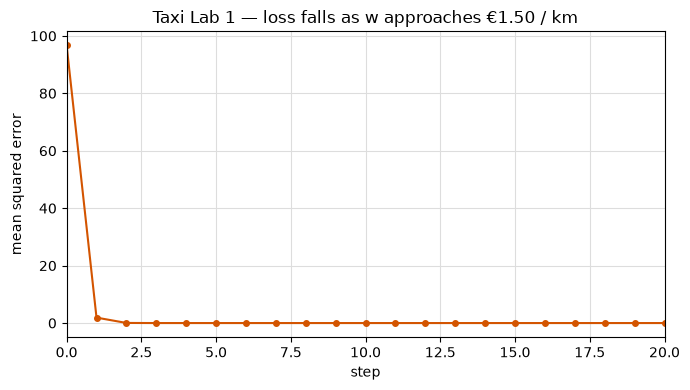

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(len(history_loss)), history_loss, color="#d35400", marker="o", markersize=4)
ax.set_xlabel("step")
ax.set_ylabel("mean squared error")
ax.set_title("Taxi Lab 1 — loss falls as w approaches €1.50 / km")
ax.set_xlim(0, steps)
ax.grid(True, color="#dddddd")
fig.tight_layout()
plt.show()